# 05 · Production review

Six simulated months from `churn simulate`: monthly cohorts with a growing population shift, a corrupted delivery in April,
and labels that only become visible 30 days after scoring. This notebook reads what the pipeline wrote (reports, prediction logs, model bundles and the MLflow registry)
and reviews whether its decisions were right.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

import json

import mlflow

from churn.data.ingest import X_y, load_split
from churn.models.bundle import load_bundle

timeline = [json.loads(line) for line in (config.REPORTS_DIR / "timeline.jsonl").read_text().splitlines()]
promotions = [json.loads(line) for line in (config.REPORTS_DIR / "promotions.jsonl").read_text().splitlines()]

pd.DataFrame({
    "month": [r["as_of"] for r in timeline],
    "shift": [r["shift"] for r in timeline],
    "validation": ["quarantined" if "validation" in r else "ok" for r in timeline],
    "max_feature_psi": [r.get("drift", {}).get("max_feature_psi") for r in timeline],
    "prediction_psi": [r.get("drift", {}).get("prediction_psi") for r in timeline],
    "signals": [", ".join(r["signals"]) or "-" for r in timeline],
    "action": [r["retraining"]["action"] for r in timeline],
    "champion": [f"v{r['champion_before']} -> v{r['champion_after']}" if r["champion_after"] != r["champion_before"] else f"v{r['champion_after']}" for r in timeline],
})

,month,shift,validation,max_feature_psi,prediction_psi,signals,action,champion
0,2026-01-01,0.0,ok,0.042,0.088,-,none,v1
1,2026-02-01,0.0,ok,0.033,0.040,-,none,v1
2,2026-03-01,1.0,ok,0.460,0.656,drift,rejected,v1
3,2026-04-01,1.5,quarantined,NaN,NaN,-,none,v1
4,2026-05-01,2.0,ok,0.321,0.591,drift,rejected,v1
5,2026-06-01,2.0,ok,0.203,0.437,drift,rejected,v1


## 1. What changed in the population

In [2]:
reference = load_split("train")
cohorts = {p.stem: pd.read_csv(p) for p in sorted(config.PORTFOLIO_DIR.glob("*.csv"))}
mix = pd.DataFrame({
    name: {
        "month-to-month": (df["contract"] == "Month-to-month").mean(),
        "fiber": (df["internet_service"] == "Fiber optic").mean(),
        "electronic check": (df["payment_method"] == "Electronic check").mean(),
        "median monthly $": df["monthly_charges"].median(),
    }
    for name, df in {"train (reference)": reference, **cohorts}.items()
}).T
mix

,month-to-month,fiber,electronic check,median monthly $
train (reference),0.544,0.443,0.341,70.650
2026-01-01,0.548,0.424,0.276,70.150
2026-02-01,0.532,0.460,0.320,70.100
2026-03-01,0.844,0.712,0.580,78.900
2026-04-01,0.880,0.000,0.652,8100.000
2026-05-01,0.800,0.692,0.484,80.525
2026-06-01,0.584,0.388,0.328,61.550


The simulated shift is clear in the cohort mix. By March, 84% of the cohort is month-to-month (54% in training) and 71% is on fiber (44%).
The April row shows the corrupted delivery: a median bill of $8,100 (cents sent as dollars) and 0% fiber (the category was renamed to `"Fiber"`).
Pandera rejected it, so it never reached the model. June is back near the reference mix even though the shift is still 2.0, because the simulation draws without replacement:
over six months 1,047 of the pool's 1,171 month-to-month customers were sampled, so by June there were few left to over-sample.

## 2. Drift, feature by feature

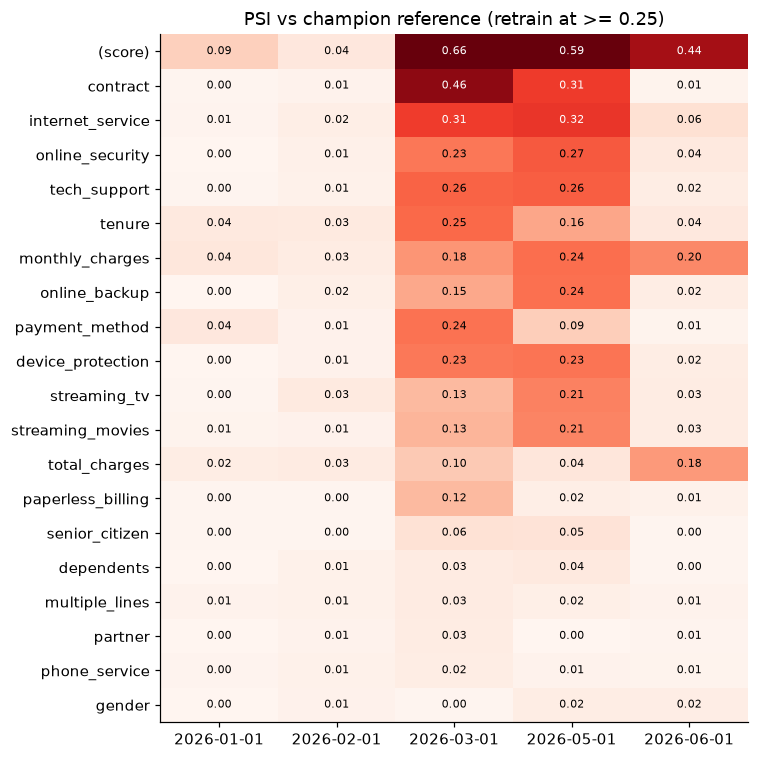

In [3]:
drift = {p.stem.removeprefix("drift_"): json.loads(p.read_text()) for p in sorted(config.REPORTS_DIR.glob("drift_*.json"))}
heat = pd.DataFrame({month: {f["feature"]: f["psi"] for f in report["features"]} for month, report in drift.items()})
heat.loc["(score)"] = [report["prediction_psi"] for report in drift.values()]
heat = heat.loc[heat.max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(heat.clip(upper=0.5), cmap="Reds", aspect="auto", vmin=0, vmax=0.5)
ax.set_xticks(range(heat.shape[1]), heat.columns)
ax.set_yticks(range(heat.shape[0]), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.3 else "black")
ax.set_title(f"PSI vs champion reference (retrain at >= {config.PSI_RETRAIN})")
fig.tight_layout()

The sampling only targets contract, internet service and payment method, but the drift spreads. `contract` (0.46) and `internet_service` (0.32) lead,
and then a block of features that were never targeted also crosses 0.2: online security, tech support, tenure, monthly charges. They move because they're correlated
with the targeted ones (fiber customers pay more, month-to-month customers are newer).
Gender, partner and dependents, which don't correlate with them, stay under 0.035. They work as a natural negative control: the monitor isn't flagging everything.

The score PSI is higher than any single feature (0.66 in March) because the shift hits several correlated drivers at once. Monitoring the score catches combined
shifts that each feature alone would rate as moderate.

## 3. Score distribution

Every valid cohort scored by the same model (v1), so the shift shown is the population's, not a model change.

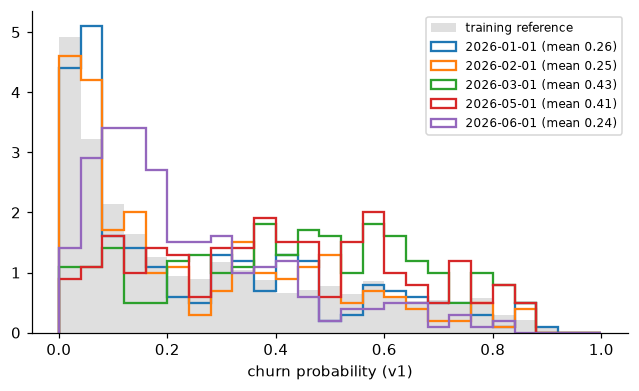

In [4]:
v1 = load_bundle(config.MODELS_DIR / "v1")
ref_scores = v1["model"].predict_proba(pd.read_csv(config.MODELS_DIR / "v1" / "reference.csv"))[:, 1]
fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(0, 1, 26)
ax.hist(ref_scores, bins=bins, density=True, histtype="stepfilled", alpha=0.25, color="grey", label="training reference")
valid = [p.stem.removeprefix("scores_") for p in sorted(config.PREDICTIONS_DIR.glob("scores_*.csv"))]
for month in valid:
    scores = v1["model"].predict_proba(cohorts[month][config.FEATURES])[:, 1]
    ax.hist(scores, bins=bins, density=True, histtype="step", lw=1.5, label=f"{month} (mean {scores.mean():.2f})")
ax.set_xlabel("churn probability (v1)")
ax.legend(fontsize=8);

## 4. Labels arrive late

In [5]:
from datetime import date, timedelta

months = [r["as_of"] for r in timeline]
maturity = pd.DataFrame(index=valid, columns=months)
for cohort in valid:
    ready = (date.fromisoformat(cohort) + timedelta(days=config.LABEL_MATURITY_DAYS)).isoformat()
    for as_of in months:
        maturity.loc[cohort, as_of] = "-" if as_of <= cohort else ("matured" if ready <= as_of else "pending")
maturity.index.name = "cohort \\ run date"
maturity

,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01
cohort \ run date,,,,,,
2026-01-01,-,matured,matured,matured,matured,matured
2026-02-01,-,-,pending,matured,matured,matured
2026-03-01,-,-,-,matured,matured,matured
2026-05-01,-,-,-,-,-,matured
2026-06-01,-,-,-,-,-,-


This is the constraint that shapes the whole retraining logic. On March 1st the February cohort is still pending: February has 28 days, so its 30-day window
closes on March 3rd. The drift signal fired that day, but the retrain could only learn from January. Drift tells you today that the inputs changed. Labels tell you a month later whether it mattered.

## 5. Realized performance

,snapshot_date,model_version,rows,gini,gini_ci95,churn_rate,predicted_churn_rate,recall,realized_net_value
0,2026-01-01,1,250,0.534,"[0.4166, 0.6652]",0.268,0.260,0.731,10454.22
2,2026-03-01,1,250,0.527,"[0.4168, 0.6338]",0.408,0.432,0.882,19767.48
4,2026-05-01,1,250,0.640,"[0.54, 0.7356]",0.436,0.406,0.917,23119.20


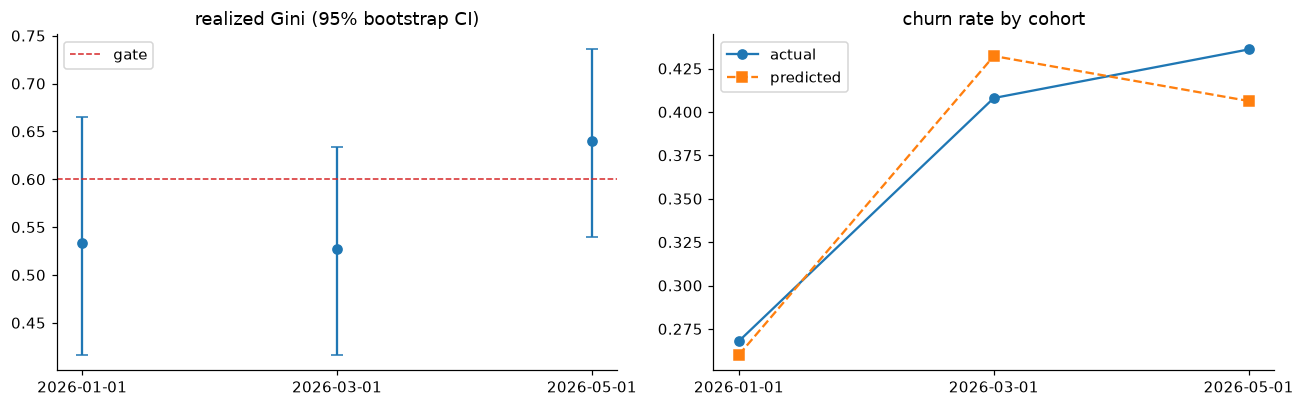

In [6]:
realized = pd.DataFrame([r["realized"] for r in timeline if r["realized"]]).drop_duplicates("snapshot_date")
low, high = realized["gini_ci95"].str[0], realized["gini_ci95"].str[1]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(realized["snapshot_date"], realized["gini"], yerr=[realized["gini"] - low, high - realized["gini"]], fmt="o", capsize=4)
axes[0].axhline(config.MIN_GINI, color="C3", ls="--", lw=1, label="gate")
axes[0].set_title("realized Gini (95% bootstrap CI)")
axes[0].legend()
axes[1].plot(realized["snapshot_date"], realized["churn_rate"], "o-", label="actual")
axes[1].plot(realized["snapshot_date"], realized["predicted_churn_rate"], "s--", label="predicted")
axes[1].set_title("churn rate by cohort")
axes[1].legend()
fig.tight_layout()
realized[["snapshot_date", "model_version", "rows", "gini", "gini_ci95", "churn_rate", "predicted_churn_rate", "recall", "realized_net_value"]]

- **The same model (v1) scored every cohort.** No challenger was promoted, so this is one model followed through six months of shift.
- Two of the three point estimates (0.534 and 0.527) are under the 0.60 gate, but no interval lies fully below it. With 250 customers per cohort the realized Gini moves ±0.1
  from sampling alone, so the trigger requires the whole CI below the gate. Performance never fired; drift did.
- **Calibration followed the population.** The actual churn rate rose from 26.8% to 40.8% and 43.6%, and the predicted rate followed (26.0%, 43.2%, 40.6%).
  That's what keeps the expected-value rule valid as the base shifts.
- Realized campaign value grew with the share of high-risk customers ($10.5k → $23.1k per 250 customers).

## 6. Promotion decisions

A retrained challenger only replaces the champion if it earns more on the frozen holdout in at least 95% of paired bootstrap resamples
(`churn.models.promotion.paired_bootstrap`). Comparing the two totals isn't enough, because differences of a few hundred dollars on 1,409 customers
are inside sampling noise. Below are the decisions the pipeline logged, and the bootstrap distributions behind them, recomputed with the same functions.

In [7]:
from churn.models.promotion import paired_bootstrap, score_holdout

holdout = load_split("holdout")
decisions = pd.DataFrame([
    {
        "challenger": f"v{p['challenger']['version']}",
        "vs": f"v{p['champion']['version']}" if p["champion"] else "-",
        "challenger_value": p["challenger"]["net_value"],
        "champion_value": p["champion"]["net_value"] if p["champion"] else None,
        "diff": p["bootstrap"]["observed_diff"] if p["bootstrap"] else None,
        "ci95": p["bootstrap"]["ci95"] if p["bootstrap"] else None,
        "win_probability": p["bootstrap"]["win_probability"] if p["bootstrap"] else None,
        "decision": "promoted" if p["promoted"] else "rejected",
    }
    for p in promotions
])
decisions

,challenger,vs,challenger_value,champion_value,diff,ci95,win_probability,decision
0,v1,-,62715.18,NaN,NaN,None,NaN,promoted
1,v2,v1,61724.73,62715.18,-990.45,"[-2077.57, -34.16]",0.021,rejected
2,v3,v1,61741.68,62715.18,-973.50,"[-2351.16, 372.55]",0.081,rejected
3,v4,v1,62003.49,62715.18,-711.69,"[-1877.39, 419.97]",0.111,rejected


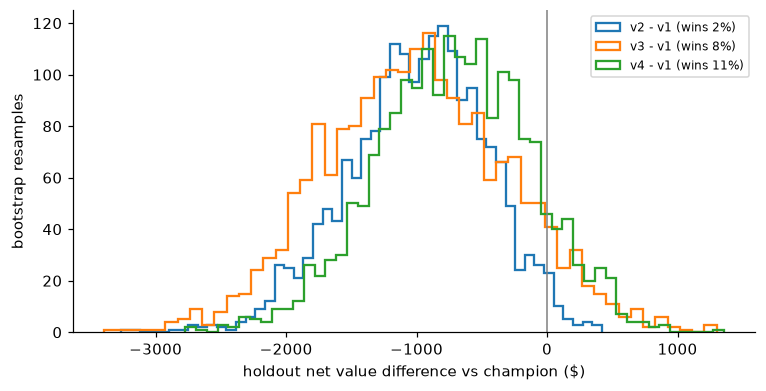

In [8]:
_, champion_gains = score_holdout(load_bundle(config.MODELS_DIR / "v1"), holdout)
rng = np.random.default_rng(config.RANDOM_STATE)
idx = rng.integers(0, len(holdout), size=(config.PROMOTION_BOOTSTRAP_SAMPLES, len(holdout)))

fig, ax = plt.subplots(figsize=(8, 3.8))
for p in promotions[1:]:
    version = p["challenger"]["version"]
    _, gains = score_holdout(load_bundle(config.MODELS_DIR / f"v{version}"), holdout)
    totals = (gains - champion_gains)[idx].sum(axis=1)
    ax.hist(totals, bins=50, histtype="step", lw=1.5, label=f"v{version} - v1 (wins {(totals > 0).mean():.0%})")
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("holdout net value difference vs champion ($)")
ax.set_ylabel("bootstrap resamples")
ax.legend(fontsize=8);

**Every retrained challenger was rejected, and correctly.** They weren't "about as good" as v1, they were worse: all three earn less on the holdout ($710-990),
and v2's interval excludes zero. They win only 2-11% of resamples, nowhere near 95%.

That's coherent with the rest of this notebook. The shift was in *who* the customers are, not in *how* churn works: the calibrated model kept tracking the actual churn rate.
Retraining on a skewed mix of cohorts tilted the challengers toward that mix without teaching them anything new, and the frozen holdout caught it.
Drift is a reason to look, not a reason to replace the model.

## 7. The registry

In [9]:
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
client = mlflow.MlflowClient()
versions = sorted(client.search_model_versions(f"name='{config.REGISTERED_MODEL_NAME}'"), key=lambda v: int(v.version))
# search_model_versions doesn't populate aliases; they live on the registered model
aliases = {}
for alias, version in client.get_registered_model(config.REGISTERED_MODEL_NAME).aliases.items():
    aliases.setdefault(str(version), []).append(alias)
pd.DataFrame([
    {
        "version": v.version,
        "aliases": ", ".join(aliases.get(str(v.version), [])) or "-",
        "trigger": v.tags.get("trigger"),
        "promotion": v.tags.get("promotion"),
        "holdout_net_value": float(v.tags.get("holdout_net_value", "nan")),
        "run_id": v.run_id[:8],
    }
    for v in versions
])

,version,aliases,trigger,promotion,holdout_net_value,run_id
0,1,champion,initial,promoted,62715.18,bb10b5f5
1,2,-,drift,rejected,61724.73,58032292
2,3,-,drift,rejected,61741.68,0acc6663
3,4,challenger,drift,rejected,62003.49,ed9572e2


In [10]:
runs = mlflow.search_runs(experiment_names=[config.EXPERIMENT_NAME], filter_string="tags.validation_status = 'PASS'")
cols = ["tags.trigger", "params.model_type", "metrics.test_gini", "metrics.test_ece", "metrics.test_net_value", "params.decision_rule"]
runs[cols].sort_values(["tags.trigger", "metrics.test_net_value"], ascending=[True, False]).rename(columns=lambda c: c.split(".", 1)[1]).head(12)

,trigger,model_type,test_gini,test_ece,test_net_value,decision_rule
0,drift,gradient_boosting,0.707,0.030,49149.84,expected_value
1,drift,random_forest,0.707,0.022,48716.88,expected_value
2,drift,logistic_regression,0.708,0.024,48305.46,expected_value
3,drift,gradient_boosting,0.726,0.042,45435.09,expected_value
4,drift,random_forest,0.723,0.038,44284.20,expected_value
5,drift,logistic_regression,0.726,0.031,43775.25,expected_value
6,drift,gradient_boosting,0.736,0.031,39326.88,expected_value
8,drift,logistic_regression,0.744,0.039,39106.68,expected_value
7,drift,random_forest,0.732,0.033,38594.37,expected_value
9,initial,gradient_boosting,0.740,0.023,36601.53,expected_value


## What the six months show

| Check | Result |
|---|---|
| Bad data reaches the model? | No. The corrupted April batch was quarantined |
| Drift detected? | Yes, in the month it started (PSI 0.46 on contract, 0.66 on the score) |
| Retrained on noise? | No. The trigger is CI-based, and promotion needs 95% of paired bootstrap resamples |
| Did retraining help? | No. Three challengers, all worse than v1 on the holdout, all rejected |
| Labels respected? | Yes. Cohorts are used only after their 30-day window |
| Calibration under shift? | Held: predicted vs actual within 1-3 points |
| Every decision traceable? | Yes. Registry versions carry trigger, promotion result, holdout value and win probability |